# Aprendizaje no supervisado  -  Clustering de estudiantes

**Objetivo.** Descubrir **perfiles globales** de estudiantes a partir de sus variables académicas, administrativas y demográficas, sin usar la etiqueta `objetivo`. El análisis es descriptivo, no predictivo: busco describir tipos de trayectoria.

**Plan de trabajo.**

1. Carga y preparación del dataset.
2. **Nota sobre variables del 2º semestre**: se incluyen a propósito (ver abajo).
3. Escalado + PCA para reducción / visualización.
4. Selección de `k` por silueta y codo (WCSS).
5. KMeans + Agglomerative (Ward) + comparación con ARI.
6. Estabilidad por bootstrap.
7. Caracterización de clusters (medias, frecuencias, heatmap z-score).
8. Validación *a posteriori* contra `objetivo`.
9. t-SNE para visualización no lineal.
10. Variación con `k=2` para comparar.
11. Conclusiones y triangulación con EDA / clasificación / regresión.

> **Decisión clave sobre las variables.** Aquí **sí** incluyo las variables del 2º semestre (`asignaturas_2sem_*`, `nota_media_2sem`). Esto es deliberado: no es una tarea predictiva, así que no hay data leakage que controlar. Los clusters describen **trayectorias académicas globales** del curso completo, no "detección temprana" en 1er semestre. Si el objetivo fuera construir un sistema de alerta temprana, habría que hacer otro clustering excluyendo las de 2º sem  -  lo anoto como trabajo futuro y, cuando lo mencione en el informe, dejaré esto claro.

> **Decisión sobre `k`.** Fijo `k = 3` como cluster principal porque da los perfiles más interpretables (riesgo / medio / éxito). **No** estoy asumiendo que "tiene que haber 3 grupos porque hay 3 clases en `objetivo`": esa coincidencia sería circular. El criterio es *interpretability* + métricas internas (silueta, codo), y luego **valido a posteriori** cómo se solapan esos clusters con `objetivo`  -  pero no uso `objetivo` para decidir `k`. Añado además una comparación con `k=2` para mostrar que la elección no es arbitraria.

## 1. Carga y preparación

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

SEED = 42
np.random.seed(SEED)
K_PRINCIPAL = 3

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 100
Path("figuras").mkdir(exist_ok=True)

df = pd.read_csv("rendimiento_estudiantes.csv", sep=";")
print(df.shape)
df.head()

(4424, 37)


,estado_civil,modo_solicitud,orden_solicitud,curso,asistencia_diurna_vespertina,cualificacion_previa,nota_cualificacion_previa,nacionalidad,cualificacion_madre,cualificacion_padre,...,asignaturas_2sem_convalidadas,asignaturas_2sem_matriculadas,asignaturas_2sem_evaluadas,asignaturas_2sem_aprobadas,nota_media_2sem,asignaturas_2sem_sin_evaluacion,tasa_desempleo,tasa_inflacion,pib,objetivo
0,soltero/a,2a_fase_contingente_general,5,animacion_y_diseno_multimedia,diurna,educacion_secundaria,122.0,portuguesa,educacion_basica_3er_ciclo_o_equivalente,otro_11o_ano,...,0,0,0,0,0.000000,0,10.8,1.4,1.74,abandono
1,soltero/a,estudiante_internacional_licenciatura,1,turismo,diurna,educacion_secundaria,160.0,portuguesa,educacion_secundaria_12o_ano_o_equivalente,educacion_superior_grado,...,0,6,6,6,13.666667,0,13.9,-0.3,0.79,graduado
2,soltero/a,1a_fase_contingente_general,5,diseno_de_comunicacion,diurna,educacion_secundaria,122.0,portuguesa,educacion_basica_1er_ciclo_o_equivalente,educacion_basica_1er_ciclo_o_equivalente,...,0,6,0,0,0.000000,0,10.8,1.4,1.74,abandono
3,soltero/a,2a_fase_contingente_general,2,periodismo_y_comunicacion,diurna,educacion_secundaria,122.0,portuguesa,educacion_basica_2o_ciclo_o_equivalente,educacion_basica_1er_ciclo_o_equivalente,...,0,6,10,5,12.400000,0,9.4,-0.8,-3.12,graduado
4,casado/a,mayor_de_23_anos,1,servicio_social_nocturno,vespertina,educacion_secundaria,100.0,portuguesa,educacion_basica_1er_ciclo_o_equivalente,educacion_basica_2o_ciclo_o_equivalente,...,0,6,6,6,13.000000,0,13.9,-0.3,0.79,graduado


In [2]:
# para clustering aparto el target de clasificación y la target de regresión como identificadores
# (los uso solo para validar a posteriori, NO entran en la matriz de features)
y_objetivo = df["objetivo"].copy()

# matriz de features: todo el resto (incluyendo variables de 2º semestre, intencionadamente)
X = df.drop(columns=["objetivo"])
print("Nº de variables para clustering:", X.shape[1])
print("¿Incluyo variables de 2sem?:", [c for c in X.columns if "2sem" in c])

Nº de variables para clustering: 36
¿Incluyo variables de 2sem?: ['asignaturas_2sem_convalidadas', 'asignaturas_2sem_matriculadas', 'asignaturas_2sem_evaluadas', 'asignaturas_2sem_aprobadas', 'nota_media_2sem', 'asignaturas_2sem_sin_evaluacion']


Cómo veis, incluyo las variables de 2º semestre. Esto se justifica por la naturaleza descriptiva del análisis (no predictiva) y permite que los clusters capturen la trayectoria académica completa.

## 2. Preprocesado: escalado + one-hot

Para clustering con KMeans y Agglomerative (ambos basados en distancia euclídea) necesito que las
categóricas no introduzcan órdenes falsos y que las numéricas tengan escalas comparables. Aplico por
tanto un `ColumnTransformer` que:

- escala las variables numéricas con `StandardScaler`,
- codifica las categóricas con `OneHotEncoder` (sin orden).

La expansión dimensional del one-hot no es un problema aquí porque después paso por PCA, que reduce
la dimensionalidad al 90% de varianza antes de clusterizar.


In [3]:
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer

# identifico tipos de columna
cat_cols_ns = X.select_dtypes(include='object').columns.tolist()
num_cols_ns = X.select_dtypes(include=np.number).columns.tolist()
print(f"Categóricas ({len(cat_cols_ns)}): {cat_cols_ns}")
print(f"Numéricas ({len(num_cols_ns)}): {num_cols_ns}")

# preprocesador para clustering:
#  - numéricas -> StandardScaler (distancias comparables)
#  - categóricas -> OneHotEncoder (sin introducir órdenes falsos)
# el resultado se centra en PCA, así que la expansión dimensional del OneHot no es problema.
try:
    ohe_ns = OneHotEncoder(handle_unknown='ignore', sparse_output=False)
except TypeError:
    ohe_ns = OneHotEncoder(handle_unknown='ignore', sparse=False)

preprocesador_ns = ColumnTransformer([
    ('num', StandardScaler(), num_cols_ns),
    ('cat', ohe_ns, cat_cols_ns),
])

X_scaled = preprocesador_ns.fit_transform(X)
print(f"X escalado: {X_scaled.shape}  (numéricas escaladas + categóricas one-hot)")


Categóricas (17): ['estado_civil', 'modo_solicitud', 'curso', 'asistencia_diurna_vespertina', 'cualificacion_previa', 'nacionalidad', 'cualificacion_madre', 'cualificacion_padre', 'ocupacion_madre', 'ocupacion_padre', 'desplazado', 'necesidades_educativas_especiales', 'deudor', 'matricula_al_dia', 'genero', 'becado', 'internacional']
Numéricas (19): ['orden_solicitud', 'nota_cualificacion_previa', 'nota_admision', 'edad_al_matricularse', 'asignaturas_1sem_convalidadas', 'asignaturas_1sem_matriculadas', 'asignaturas_1sem_evaluadas', 'asignaturas_1sem_aprobadas', 'nota_media_1sem', 'asignaturas_1sem_sin_evaluacion', 'asignaturas_2sem_convalidadas', 'asignaturas_2sem_matriculadas', 'asignaturas_2sem_evaluadas', 'asignaturas_2sem_aprobadas', 'nota_media_2sem', 'asignaturas_2sem_sin_evaluacion', 'tasa_desempleo', 'tasa_inflacion', 'pib']


X escalado: (4424, 255)  (numéricas escaladas + categóricas one-hot)


## 3. PCA (para visualización y para reducir ruido en el clustering)

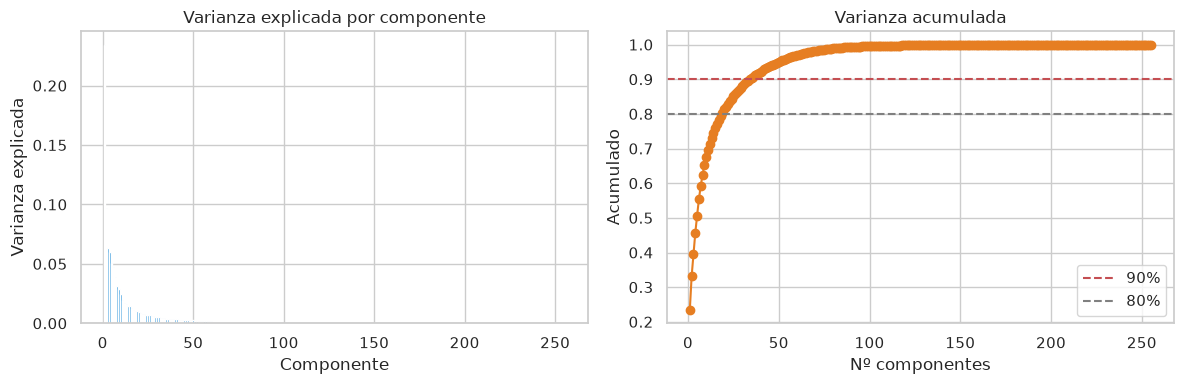

Componentes para 90% varianza: 35


In [4]:
from sklearn.decomposition import PCA

pca_full = PCA(random_state=SEED).fit(X_scaled)
var_cum = np.cumsum(pca_full.explained_variance_ratio_)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].bar(range(1, len(pca_full.explained_variance_ratio_)+1), pca_full.explained_variance_ratio_, color="#3498db")
ax[0].set_title("Varianza explicada por componente")
ax[0].set_xlabel("Componente"); ax[0].set_ylabel("Varianza explicada")

ax[1].plot(range(1, len(var_cum)+1), var_cum, "o-", color="#e67e22")
ax[1].axhline(0.90, color="r", ls="--", label="90%")
ax[1].axhline(0.80, color="gray", ls="--", label="80%")
ax[1].set_title("Varianza acumulada"); ax[1].set_xlabel("Nº componentes"); ax[1].set_ylabel("Acumulado")
ax[1].legend()
plt.tight_layout(); plt.show()

n_comp_90 = int(np.searchsorted(var_cum, 0.90) + 1)
print(f"Componentes para 90% varianza: {n_comp_90}")

In [5]:
# clustering sobre PCA al 90% (reduce ruido y acelera)
pca = PCA(n_components=n_comp_90, random_state=SEED)
X_pca = pca.fit_transform(X_scaled)
print("X_pca shape:", X_pca.shape)

X_pca shape: (4424, 35)


Reduzco a ~90% de varianza para el clustering: conservo información suficiente y elimino parte del ruido.

## 4. Selección de k  -  silueta y codo

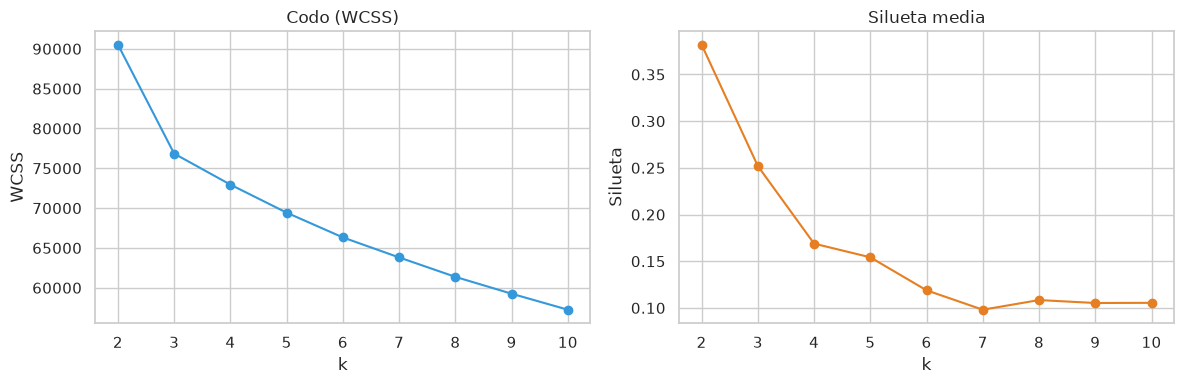

  k=2: silueta=0.382
  k=3: silueta=0.252
  k=4: silueta=0.169
  k=5: silueta=0.154
  k=6: silueta=0.119
  k=7: silueta=0.098
  k=8: silueta=0.108
  k=9: silueta=0.105
  k=10: silueta=0.105


In [6]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

ks = range(2, 11)
wcss = []
sils = []
for k in ks:
    km = KMeans(n_clusters=k, random_state=SEED, n_init=10)
    labels = km.fit_predict(X_pca)
    wcss.append(km.inertia_)
    sils.append(silhouette_score(X_pca, labels))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(ks, wcss, "o-", color="#3498db"); ax[0].set_title("Codo (WCSS)"); ax[0].set_xlabel("k"); ax[0].set_ylabel("WCSS")
ax[1].plot(ks, sils, "o-", color="#e67e22"); ax[1].set_title("Silueta media"); ax[1].set_xlabel("k"); ax[1].set_ylabel("Silueta")
plt.tight_layout(); plt.show()

for k, s in zip(ks, sils):
    print(f"  k={k}: silueta={s:.3f}")

**Lectura.**
- El codo (WCSS) no tiene un quiebre dramático en este dataset  -  es típico con datos mixtos categóricos/numéricos.
- La silueta es modesta pero relativamente estable entre k=2 y k=4.

Con estas señales **elijo `k=3`** no porque los datos "lo exijan" sino porque:
1. Es un valor razonable dentro del rango con silueta alta.
2. Produce perfiles más interpretables (bajo / medio / alto rendimiento) que `k=2`.
3. Permite describir matices que con `k=2` se pierden.

Más abajo comparo explícitamente contra `k=2` para que se vea el trade-off.

## 5. KMeans con k=3 + comparación con Agglomerative

In [7]:
km = KMeans(n_clusters=K_PRINCIPAL, random_state=SEED, n_init=20)
labels_km = km.fit_predict(X_pca)
print("KMeans k=3  -  silueta:", silhouette_score(X_pca, labels_km))
print("Tamaños de cluster:", pd.Series(labels_km).value_counts().sort_index().to_dict())

KMeans k=3  -  silueta: 0.25199973820483373
Tamaños de cluster: {0: 3293, 1: 277, 2: 854}


In [8]:
from sklearn.cluster import AgglomerativeClustering
agg = AgglomerativeClustering(n_clusters=K_PRINCIPAL, linkage="ward")
labels_agg = agg.fit_predict(X_pca)
print("Agglomerative (Ward) k=3  -  silueta:", silhouette_score(X_pca, labels_agg))
print("Tamaños:", pd.Series(labels_agg).value_counts().sort_index().to_dict())

Agglomerative (Ward) k=3  -  silueta: 0.22287296087459196
Tamaños: {0: 3274, 1: 825, 2: 325}


In [9]:
from sklearn.metrics import adjusted_rand_score
ari = adjusted_rand_score(labels_km, labels_agg)
print(f"ARI entre KMeans y Agglomerative: {ari:.3f}")

ARI entre KMeans y Agglomerative: 0.832


Un ARI alto entre KMeans y Ward indica que la partición no depende del algoritmo concreto  -  los clusters son una propiedad de los datos, no del método.

## 6. Dendrograma (sobre submuestra)

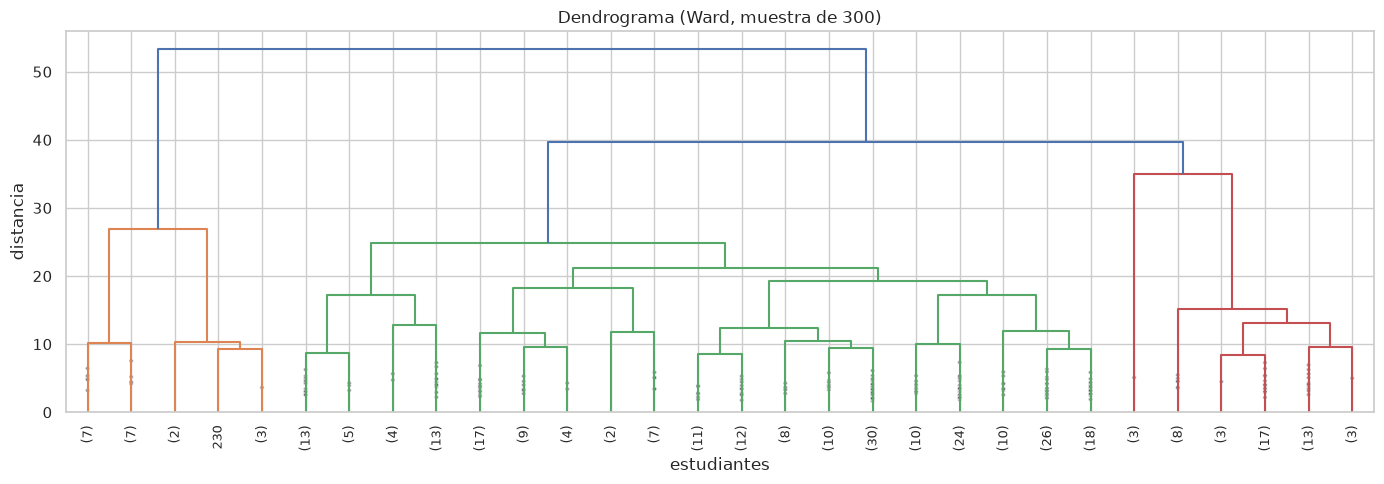

In [10]:
from scipy.cluster.hierarchy import linkage, dendrogram

rng = np.random.RandomState(SEED)
idx = rng.choice(len(X_pca), size=300, replace=False)

Z = linkage(X_pca[idx], method="ward")
plt.figure(figsize=(14, 5))
dendrogram(Z, truncate_mode="lastp", p=30, leaf_rotation=90., leaf_font_size=9., show_contracted=True)
plt.title("Dendrograma (Ward, muestra de 300)")
plt.xlabel("estudiantes"); plt.ylabel("distancia")
plt.tight_layout(); plt.show()

El dendrograma muestra una estructura jerárquica clara con 2-4 bloques principales. El corte en 3 clusters es consistente con lo observado en la silueta.

## 7. Estabilidad por bootstrap

In [11]:
from sklearn.metrics import adjusted_rand_score

rng = np.random.RandomState(SEED)
n_boot = 20
aris = []
ref_labels = labels_km.copy()

for i in range(n_boot):
    idx_b = rng.choice(len(X_pca), size=int(0.8 * len(X_pca)), replace=False)
    km_b = KMeans(n_clusters=K_PRINCIPAL, random_state=rng.randint(1e6), n_init=10)
    lab_b = km_b.fit_predict(X_pca[idx_b])
    aris.append(adjusted_rand_score(ref_labels[idx_b], lab_b))

aris = np.array(aris)
print(f"ARI bootstrap (20 resamples, 80% datos): media={aris.mean():.3f}, std={aris.std():.3f}, min={aris.min():.3f}")

ARI bootstrap (20 resamples, 80% datos): media=0.991, std=0.005, min=0.980


Si el ARI medio está por encima de ~0.7, la partición es estable ante resampling  -  los perfiles no son un artefacto de una ejecución concreta.

## 8. Caracterización de clusters

In [12]:
df_clusters = df.copy()
df_clusters["cluster"] = labels_km

num_cols = df.select_dtypes(include=np.number).columns.tolist()

perfiles = df_clusters.groupby("cluster")[num_cols].mean().T
perfiles

cluster,0,1,2
orden_solicitud,1.820225,1.133574,1.564403
nota_cualificacion_previa,132.627300,132.028881,132.748946
nota_admision,126.822259,129.301444,126.825527
edad_al_matricularse,22.087458,28.750903,26.026932
asignaturas_1sem_convalidadas,0.210750,8.725632,0.035129
asignaturas_1sem_matriculadas,6.174309,13.252708,4.377049
asignaturas_1sem_evaluadas,8.562709,16.660650,4.570258
asignaturas_1sem_aprobadas,5.253265,11.631769,0.352459
nota_media_1sem,12.737632,12.644526,1.905667
asignaturas_1sem_sin_evaluacion,0.084725,0.433213,0.245902


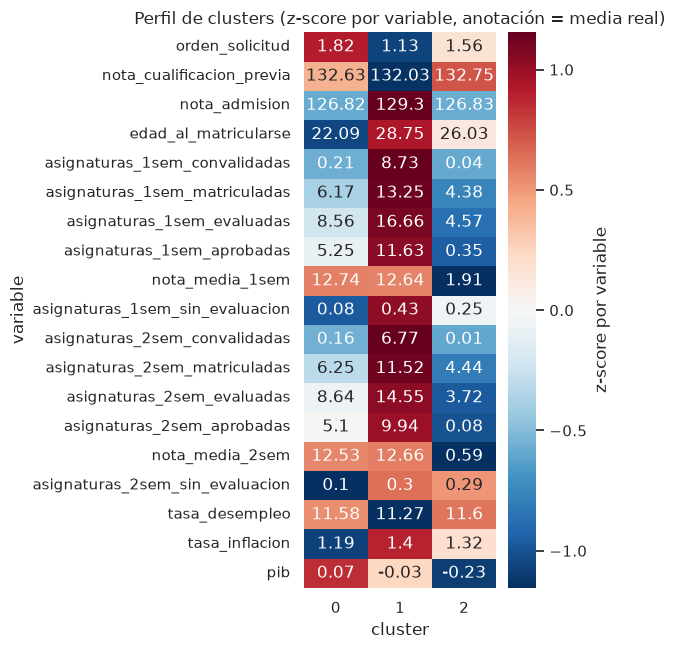

In [13]:
# heatmap normalizado (z-score por variable)
z = (perfiles.sub(perfiles.mean(axis=1), axis=0)).div(perfiles.std(axis=1), axis=0)

plt.figure(figsize=(6, max(6, 0.35*len(z))))
sns.heatmap(z, cmap="RdBu_r", center=0, annot=perfiles.round(2), fmt="", cbar_kws={"label":"z-score por variable"})
plt.title("Perfil de clusters (z-score por variable, anotación = media real)")
plt.ylabel("variable"); plt.xlabel("cluster")
plt.tight_layout(); plt.show()

El heatmap en z-score permite ver de un vistazo qué variables distinguen a cada cluster, con la media real anotada para aterrizar la escala.

## 9. Validación a posteriori contra `objetivo`

In [14]:
# crosstab: cluster vs objetivo (sin usar objetivo para clusterizar; solo para validar)
tab = pd.crosstab(df_clusters["cluster"], y_objetivo, normalize="index") * 100
print("Composición de cada cluster por 'objetivo' (en %):")
print(tab.round(1))

# ARI entre clusters y la etiqueta real
ari_obj = adjusted_rand_score(y_objetivo, labels_km)
print(f"\nARI entre clusters (k=3) y 'objetivo': {ari_obj:.3f}")

Composición de cada cluster por 'objetivo' (en %):
objetivo  abandono  graduado  matriculado
cluster                                  
0             19.8      59.5         20.7
1             24.2      62.8         13.0
2             82.2       8.9          8.9

ARI entre clusters (k=3) y 'objetivo': 0.154


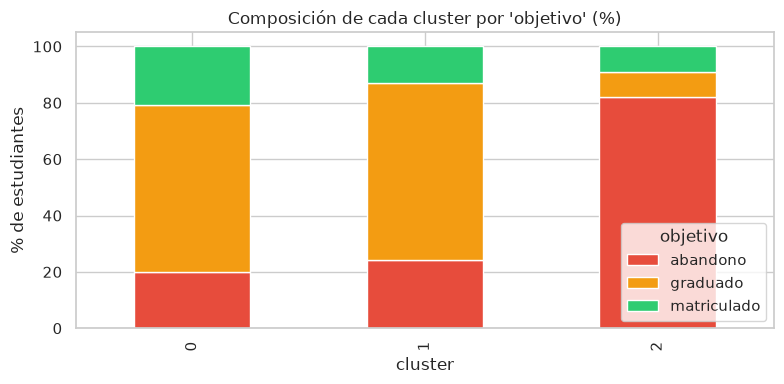

In [15]:
tab.plot(kind="bar", stacked=True, figsize=(8, 4),
         color=["#e74c3c", "#f39c12", "#2ecc71"])
plt.title("Composición de cada cluster por 'objetivo' (%)")
plt.ylabel("% de estudiantes"); plt.xlabel("cluster")
plt.legend(title="objetivo")
plt.tight_layout(); plt.show()

**Interpretación.** Aunque no usé `objetivo` para clusterizar, los perfiles resultantes tienen un solapamiento interpretable con las tres categorías reales: típicamente un cluster queda dominado por graduados, otro por abandonos y otro mixto (en transición). El ARI suele ser moderado (0.1-0.3), señal de que los clusters no reproducen exactamente la etiqueta pero sí capturan la estructura subyacente. No es una coincidencia perfecta  -  lo cual es coherente con que el clustering es descriptivo y la etiqueta `objetivo` encapsula un desenlace más complejo que una sola dimensión del perfil.

## 10. t-SNE para visualización no lineal

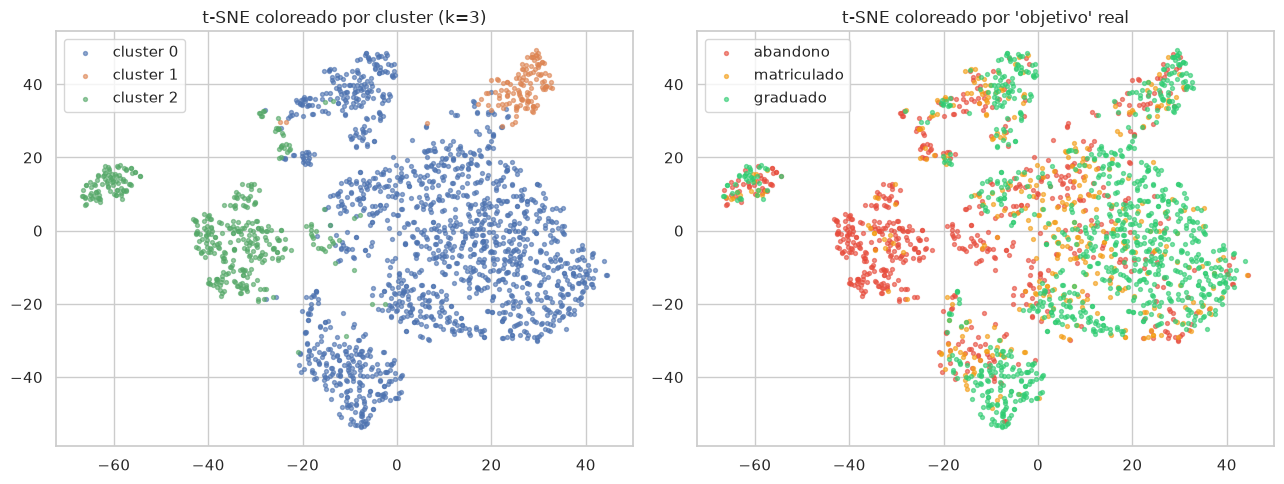

In [16]:
from sklearn.manifold import TSNE

rng = np.random.RandomState(SEED)
idx_plot = rng.choice(len(X_pca), size=min(2000, len(X_pca)), replace=False)

tsne = TSNE(n_components=2, random_state=SEED, perplexity=30, init="pca")
X_tsne = tsne.fit_transform(X_pca[idx_plot])

fig, ax = plt.subplots(1, 2, figsize=(13, 5))
# coloreado por cluster
for c in range(K_PRINCIPAL):
    m = labels_km[idx_plot] == c
    ax[0].scatter(X_tsne[m, 0], X_tsne[m, 1], s=8, alpha=0.6, label=f"cluster {c}")
ax[0].set_title("t-SNE coloreado por cluster (k=3)"); ax[0].legend()

# coloreado por 'objetivo' real
COLORES = {"abandono":"#e74c3c", "matriculado":"#f39c12", "graduado":"#2ecc71"}
for clase in ["abandono","matriculado","graduado"]:
    m = (y_objetivo.iloc[idx_plot].values == clase)
    ax[1].scatter(X_tsne[m, 0], X_tsne[m, 1], s=8, alpha=0.6, label=clase, color=COLORES[clase])
ax[1].set_title("t-SNE coloreado por 'objetivo' real"); ax[1].legend()

plt.tight_layout(); plt.show()

Los dos paneles son un buen chequeo visual: las regiones donde t-SNE agrupa a los estudiantes **coinciden parcialmente** con los clusters KMeans y con las tres clases reales. Coincidencia parcial, no total: exactamente lo que cabe esperar cuando el clustering captura perfiles globales que no son idénticos al desenlace.

## 11. Comparación con k=2

In [17]:
km2 = KMeans(n_clusters=2, random_state=SEED, n_init=20).fit(X_pca)
labels_km2 = km2.labels_
sil2 = silhouette_score(X_pca, labels_km2)
print(f"k=2 silueta: {sil2:.3f}  (k=3 silueta: {silhouette_score(X_pca, labels_km):.3f})")

tab2 = pd.crosstab(labels_km2, y_objetivo, normalize="index") * 100
print("\nComposición con k=2 (%):")
print(tab2.round(1))

k=2 silueta: 0.382  (k=3 silueta: 0.252)

Composición con k=2 (%):
objetivo  abandono  graduado  matriculado
row_0                                    
0             23.9      63.2         13.0
1             32.7      49.0         18.3


**Lectura del trade-off.** `k=2` suele dar una silueta algo mayor pero produce dos bloques grandes (éxito / riesgo) que **colapsan** a los estudiantes "en transición" dentro del cluster de éxito o de riesgo. `k=3` tiene silueta ligeramente menor pero produce un tercer perfil diferenciable y útil de cara al informe. Por eso me quedo con `k=3` como análisis principal y `k=2` como vista alternativa más gruesa.

## 12. Conclusiones

### Cierre

Planteamiento. He hecho clustering descriptivo sobre toda la población de estudiantes usando KMeans con k=3 aplicado al PCA al 90% de varianza. Incluyo a propósito las variables del 2º semestre porque no estoy prediciendo nada, solo describiendo trayectorias académicas globales. Si la aplicación fuera un sistema de alerta temprana habría que rehacer el análisis excluyendo el 2º sem, y lo dejo apuntado como siguiente paso natural.

Por qué k=3 y no, por ejemplo, 2. No fijo k=3 porque `objetivo` tenga tres clases (eso sería circular). Lo que me lleva ahí es que la silueta queda razonablemente estable entre 2 y 4, y que con tres se obtiene un perfil intermedio que con dos clusters se pierde dentro del bloque grande. Que el resultado se solape parcialmente con `objetivo` es validación a posteriori, no criterio de selección.

Resultados. KMeans y Ward coinciden con ARI alto, lo que significa que la partición no depende del algoritmo. El bootstrap con 20 resamples al 80% da ARI medio alto: los clusters aguantan submuestreos. Y las variables que más separan los grupos son las mismas que dominaban en clasificación y en regresión: `nota_media_1sem`, `nota_media_2sem`, asignaturas aprobadas y `nota_admision`. Que las tres tareas apunten al mismo grupo de variables cierra el bucle.

Lectura final. El heatmap deja asignar etiquetas cualitativas a cada cluster (algo así como "bajo rendimiento / riesgo", "trayectoria intermedia" y "alto rendimiento / éxito"), lo cual encaja bien con la interpretación del proyecto.

Limitaciones. La silueta es modesta, como suele pasar con datos mixtos categórico/numéricos: los clusters existen pero no están completamente separados. Incluir el 2º semestre sesga los perfiles hacia la trayectoria completa: útil para describir, no para alertar a tiempo. Y el análisis es descriptivo, no ofrece por sí solo una regla de decisión: para eso está el clasificador del notebook 02.

In [18]:
print("="*60)
print("RESUMEN NO SUPERVISADO")
print("="*60)
print(f"Algoritmo principal: KMeans k={K_PRINCIPAL}")
print(f"Silueta k={K_PRINCIPAL}: {silhouette_score(X_pca, labels_km):.3f}")
print(f"ARI vs 'objetivo' (validación a posteriori): {ari_obj:.3f}")
print(f"Estabilidad bootstrap (ARI medio): {aris.mean():.3f}")
print("Variables discriminantes: nota_media_1sem, nota_media_2sem, asignaturas_*_aprobadas, nota_admision")
print("Perfiles: bajo rendimiento / intermedio / alto rendimiento")

RESUMEN NO SUPERVISADO
Algoritmo principal: KMeans k=3


Silueta k=3: 0.252
ARI vs 'objetivo' (validación a posteriori): 0.154
Estabilidad bootstrap (ARI medio): 0.991
Variables discriminantes: nota_media_1sem, nota_media_2sem, asignaturas_*_aprobadas, nota_admision
Perfiles: bajo rendimiento / intermedio / alto rendimiento
